feature_engineering_selection

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

import joblib

In [2]:
# Load cleaned dataset from EDA notebook

file_path = Path("../data/processed/loan_approval_cleaned.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 32409
Number of columns: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2


In [3]:
# Check existing features in the dataset

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

Column Names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 32409 entries, 0 to 32408
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32409 non-null  int64  
 1   person_income               32409 non-null  int64  
 2   person_home_ownership       32409 non-null  str    
 3   person_emp_length           31522 non-null  float64
 4   loan_intent                 32409 non-null  str    
 5   loan_grade                  32409 non-null  str    
 6   loan_amnt                   32409 non-null  int64  
 7   loan_int_rate               29315 non-null  float64
 8   loan_status                 32409 non-null  int64  
 9   

In [4]:
# Separate input features and target variable

X = df.drop(columns=["loan_status"])

y = df["loan_status"]

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)


Input Features (X): (32409, 11)
Target Variable (y): (32409,)


In [5]:
print("\nInput Feature Names:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())


Input Feature Names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Target Distribution:
loan_status
0    25321
1     7088
Name: count, dtype: int64


In [6]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (25927, 11)
Testing Features: (6482, 11)
Training Target: (25927,)
Testing Target: (6482,)


In [7]:
# Create new features

X_train = X_train.copy()
X_test = X_test.copy()

for data in [X_train, X_test]:

    data["loan_to_income_ratio"] = (
        data["loan_amnt"] /
        data["person_income"].replace(0, np.nan)
    )

    data["employment_to_age_ratio"] = (
        data["person_emp_length"] /
        data["person_age"].replace(0, np.nan)
    )

    data["credit_history_to_age_ratio"] = (
        data["cb_person_cred_hist_length"] /
        data["person_age"].replace(0, np.nan)
    )

print("Feature Engineering Completed!")

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Feature Engineering Completed!
Training Shape: (25927, 14)
Testing Shape: (6482, 14)


In [8]:
# Identify numerical features
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nTotal Numerical Features:", len(numerical_features))

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Categorical Features:", len(categorical_features))

Numerical Features:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_to_income_ratio', 'employment_to_age_ratio', 'credit_history_to_age_ratio']

Total Numerical Features: 10

Categorical Features:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Total Categorical Features: 4


In [9]:
# Handle infinite values before preprocessing
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# Fit preprocessing pipeline on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Get processed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert processed arrays into DataFrames
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Preprocessing Completed Successfully!")

print("\nTraining Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nProcessed Training Data:")
display(X_train_processed.head())

Preprocessing Completed Successfully!

Training Data Shape: (25927, 29)
Testing Data Shape: (6482, 29)

Processed Training Data:


,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,num__loan_to_income_ratio,num__employment_to_age_ratio,num__credit_history_to_age_ratio,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
31112,1.510006,0.365413,3.587041,0.066435,-0.336807,-0.471326,2.526875,-0.495240,2.547724,2.545144,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5364,-0.436694,-0.300768,0.563333,-0.171904,1.514924,-0.002815,-0.443329,-0.005785,0.797245,-0.369870,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
13349,-0.274469,0.460581,-0.948522,1.655355,-0.012511,0.465695,-0.690846,0.482449,-1.013392,-0.847253,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
31695,2.158905,0.436066,-0.696546,1.019787,-0.025483,0.090887,2.279358,0.091062,-0.936038,1.832754,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
24075,1.185556,-0.510139,-0.696546,0.066435,0.691212,0.840504,0.051705,0.802078,-0.873352,-0.247585,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [11]:
# Feature Selection using SelectKBest

selector = SelectKBest(
    score_func=f_classif,
    k=15
)

# Fit feature selection on training data
X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

# Apply same selection to testing data
X_test_selected = selector.transform(
    X_test_processed
)

# Get selected feature names
selected_features = X_train_processed.columns[
    selector.get_support()
].tolist()

print("Feature Selection Completed Successfully!")

print("\nTotal Features Before Selection:",
      X_train_processed.shape[1])

print("Total Features After Selection:",
      X_train_selected.shape[1])

print("\nSelected Features:")
for feature in selected_features:
    print(feature)

Feature Selection Completed Successfully!

Total Features Before Selection: 29
Total Features After Selection: 15

Selected Features:
num__person_income
num__loan_amnt
num__loan_int_rate
num__loan_percent_income
num__loan_to_income_ratio
cat__person_home_ownership_MORTGAGE
cat__person_home_ownership_OWN
cat__person_home_ownership_RENT
cat__loan_grade_A
cat__loan_grade_B
cat__loan_grade_D
cat__loan_grade_E
cat__loan_grade_F
cat__cb_person_default_on_file_N
cat__cb_person_default_on_file_Y


In [12]:
# Create DataFrame with feature selection scores

feature_scores = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Score": selector.scores_,
    "Selected": selector.get_support()
})

# Sort features by highest score
feature_scores = feature_scores.sort_values(
    by="Score",
    ascending=False
).reset_index(drop=True)

# Add ranking
feature_scores["Rank"] = feature_scores.index + 1

print("Feature Selection Scores and Rankings:")

display(feature_scores)

Feature Selection Scores and Rankings:


,Feature,Score,Selected,Rank
0,num__loan_to_income_ratio,4542.127748,True,1
1,num__loan_percent_income,4373.091817,True,2
2,num__loan_int_rate,2936.581795,True,3
3,cat__loan_grade_D,2931.347335,True,4
4,cat__person_home_ownership_RENT,1577.708294,True,5
5,cat__loan_grade_A,1087.693425,True,6
6,cat__person_home_ownership_MORTGAGE,964.078615,True,7
7,cat__loan_grade_E,893.326680,True,8
8,cat__cb_person_default_on_file_Y,772.928808,True,9
9,cat__cb_person_default_on_file_N,772.928808,True,10


In [14]:
# =====================================================
# SAVE PREPROCESSOR AND FEATURE SELECTOR
# =====================================================

import joblib
from pathlib import Path

# Define existing models folder
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save fitted preprocessor
joblib.dump(
    preprocessor,
    MODELS_DIR / "preprocessor.pkl"
)

# Save fitted feature selector
joblib.dump(
    selector,
    MODELS_DIR / "feature_selector.pkl"
)

# Verify saved files
print("Preprocessor saved successfully!")
print("Feature selector saved successfully!")
print("Selected features:", selector.get_support().sum())

print("\nSaved files:")
print(MODELS_DIR / "preprocessor.pkl")
print(MODELS_DIR / "feature_selector.pkl")

Preprocessor saved successfully!
Feature selector saved successfully!
Selected features: 15

Saved files:
..\models\preprocessor.pkl
..\models\feature_selector.pkl


In [15]:
import joblib
from pathlib import Path

MODELS_DIR = Path("../models")

preprocessor = joblib.load(MODELS_DIR / "preprocessor.pkl")
selector = joblib.load(MODELS_DIR / "feature_selector.pkl")

print("Preprocessor loaded successfully!")
print("Feature selector loaded successfully!")
print("Selected features:", selector.get_support().sum())

Preprocessor loaded successfully!
Feature selector loaded successfully!
Selected features: 15


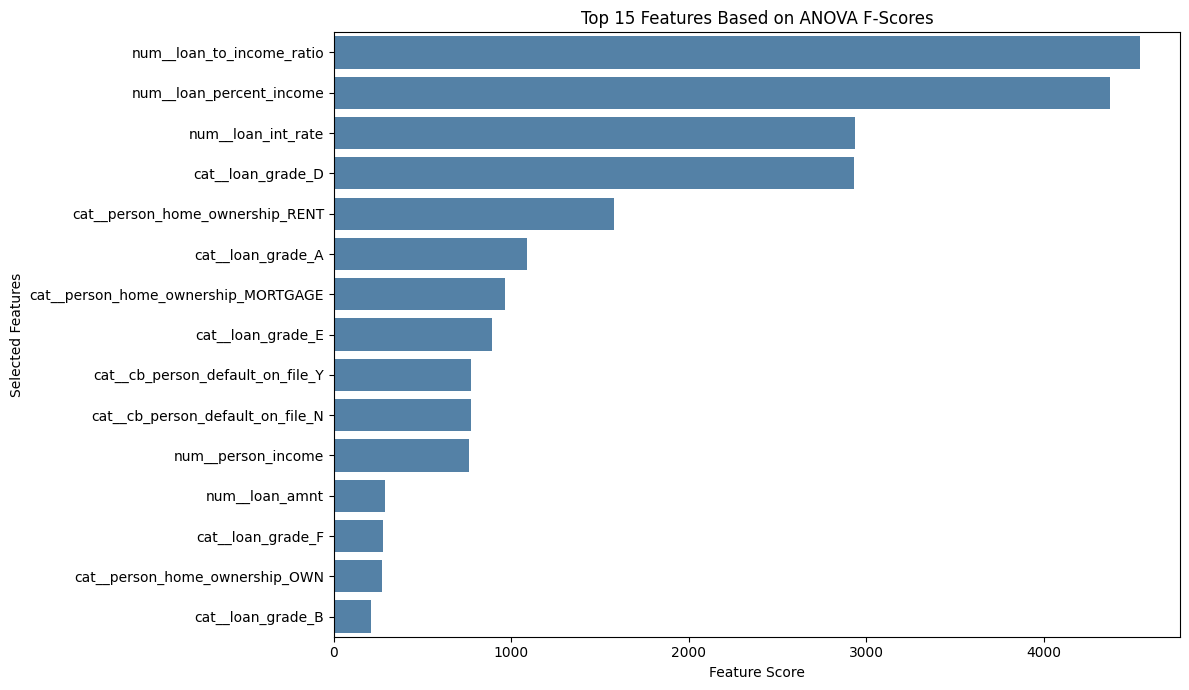

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 15 features
top_15_features = feature_scores.head(15)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_15_features,
    x="Score",
    y="Feature",
    color="steelblue"
)

plt.title("Top 15 Features Based on ANOVA F-Scores")
plt.xlabel("Feature Score")
plt.ylabel("Selected Features")

plt.tight_layout()
plt.show()

In [17]:
# Convert selected training features into DataFrame
X_train_selected = pd.DataFrame(
    X_train_selected,
    columns=selected_features,
    index=X_train.index
)

# Convert selected testing features into DataFrame
X_test_selected = pd.DataFrame(
    X_test_selected,
    columns=selected_features,
    index=X_test.index
)

print("Selected Feature DataFrames Created Successfully!")

print("\nTraining Data Shape:", X_train_selected.shape)
print("Testing Data Shape:", X_test_selected.shape)

print("\nSelected Training Features:")
display(X_train_selected.head())

print("\nSelected Testing Features:")
display(X_test_selected.head())

Selected Feature DataFrames Created Successfully!

Training Data Shape: (25927, 15)
Testing Data Shape: (6482, 15)

Selected Training Features:


,num__person_income,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__loan_to_income_ratio,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
31112,0.365413,0.066435,-0.336807,-0.471326,-0.495240,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5364,-0.300768,-0.171904,1.514924,-0.002815,-0.005785,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
13349,0.460581,1.655355,-0.012511,0.465695,0.482449,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
31695,0.436066,1.019787,-0.025483,0.090887,0.091062,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
24075,-0.510139,0.066435,0.691212,0.840504,0.802078,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0



Selected Testing Features:


,num__person_income,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__loan_to_income_ratio,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
16587,-0.434080,-0.759804,0.000461,-0.565028,-0.551417,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
26852,0.803189,4.038737,0.798230,1.402717,1.434678,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
19721,-0.453038,0.225327,-0.216818,0.840504,0.853447,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
24055,-0.395936,0.066435,-0.122772,0.465695,0.482449,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
24943,-0.673600,0.384219,-0.210332,2.058632,2.093859,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [18]:
# Final Feature Engineering and Selection Verification

print("Feature Engineering and Selection Completed!")

print("\nTraining Dataset:", X_train_selected.shape)
print("Testing Dataset:", X_test_selected.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nSelected Features:")
for feature in selected_features:
    print(feature)

print("\nMissing Values in Training:",
      X_train_selected.isnull().sum().sum())

print("Missing Values in Testing:",
      X_test_selected.isnull().sum().sum())

Feature Engineering and Selection Completed!

Training Dataset: (25927, 15)
Testing Dataset: (6482, 15)

Training Target: (25927,)
Testing Target: (6482,)

Selected Features:
num__person_income
num__loan_amnt
num__loan_int_rate
num__loan_percent_income
num__loan_to_income_ratio
cat__person_home_ownership_MORTGAGE
cat__person_home_ownership_OWN
cat__person_home_ownership_RENT
cat__loan_grade_A
cat__loan_grade_B
cat__loan_grade_D
cat__loan_grade_E
cat__loan_grade_F
cat__cb_person_default_on_file_N
cat__cb_person_default_on_file_Y

Missing Values in Training: 0
Missing Values in Testing: 0


In [19]:
from pathlib import Path

# Combine selected training features with target
train_final = X_train_selected.copy()
train_final["loan_status"] = y_train

# Combine selected testing features with target
test_final = X_test_selected.copy()
test_final["loan_status"] = y_test

# Mark rows to preserve the original train-test split
train_final["dataset_split"] = "train"
test_final["dataset_split"] = "test"

# Combine into one dataset
final_df = pd.concat(
    [train_final, test_final],
    ignore_index=True
)

# Save CSV
output_path = Path(
    "../data/processed/loan_approval_final_features.csv"
)

final_df.to_csv(output_path, index=False)

print("Final dataset saved successfully!")
print("Dataset Shape:", final_df.shape)

display(final_df.head())

Final dataset saved successfully!
Dataset Shape: (32409, 17)


,num__person_income,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__loan_to_income_ratio,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y,loan_status,dataset_split
0,0.365413,0.066435,-0.336807,-0.471326,-0.495240,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,train
1,-0.300768,-0.171904,1.514924,-0.002815,-0.005785,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0,train
2,0.460581,1.655355,-0.012511,0.465695,0.482449,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,train
3,0.436066,1.019787,-0.025483,0.090887,0.091062,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0,train
4,-0.510139,0.066435,0.691212,0.840504,0.802078,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1,train
